In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
import random

# Semilla para que los resultados sean reproducibles
np.random.seed(42)
random.seed(42)

# Cantidad de clientes
n = 200

# Nombres base
nombres = [
    "Laura Gómez",
    "Carlos Pérez",
    "Ana Torres",
    "Andrés Rodríguez",
    "Mariana López",
    "Santiago Martínez",
    "Valentina García",
    "Daniel Hernández",
    "Camila Ramírez",
    "Sebastián Castro",
    "Natalia Vargas",
    "Juan Moreno",
    "Paula Jiménez",
    "David Rojas",
    "Sofía Morales",
    "Miguel Sánchez",
    "Isabella Ortiz",
    "Felipe Navarro",
    "Daniela Romero",
    "Alejandro Ruiz"
]

# Crear 200 nombres únicos agregando un identificador
clientes = [
    f"{random.choice(nombres)} {i + 1}"
    for i in range(n)
]

# Generar variables
edad = np.random.randint(18, 71, n)

ingresos = np.random.randint(1_200_000, 7_000_001, n)

frecuencia_compra = np.random.randint(1, 16, n)

productos_adquiridos = np.random.randint(1, 21, n)

tiempo_cliente = np.random.randint(1, 73, n)

satisfaccion = np.random.randint(1, 6, n)

# Crear un indicador de riesgo
riesgo = (
    (satisfaccion <= 2) * 3
    + (frecuencia_compra <= 3) * 2
    + (tiempo_cliente <= 12) * 1
    + (productos_adquiridos <= 4) * 1
    + (ingresos < 2_000_000) * 1
)

# Convertir el indicador de riesgo en una probabilidad
probabilidad_abandono = np.clip(
    0.05 + riesgo * 0.15,
    0.05,
    0.90
)

# Crear variable objetivo
abandono = np.random.binomial(
    1,
    probabilidad_abandono
)

# Crear DataFrame
df = pd.DataFrame({
    "nombre": clientes,
    "edad": edad,
    "ingresos": ingresos,
    "frecuencia_compra": frecuencia_compra,
    "productos_adquiridos": productos_adquiridos,
    "tiempo_cliente": tiempo_cliente,
    "satisfaccion": satisfaccion,
    "abandono": abandono
})

df.head()

,nombre,edad,ingresos,frecuencia_compra,productos_adquiridos,tiempo_cliente,satisfaccion,abandono
0,Andrés Rodríguez 1,56,6897469,13,2,62,5,0
1,Laura Gómez 2,69,3435000,10,19,65,3,0
2,Camila Ramírez 3,46,5522252,7,9,32,1,1
3,Daniel Hernández 4,32,1602690,10,7,34,2,0
4,Daniel Hernández 5,60,5893350,3,4,72,4,1


In [3]:
df.shape

(200, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   nombre                200 non-null    str  
 1   edad                  200 non-null    int32
 2   ingresos              200 non-null    int32
 3   frecuencia_compra     200 non-null    int32
 4   productos_adquiridos  200 non-null    int32
 5   tiempo_cliente        200 non-null    int32
 6   satisfaccion          200 non-null    int32
 7   abandono              200 non-null    int32
dtypes: int32(7), str(1)
memory usage: 7.2 KB


In [5]:
df.describe()

,edad,ingresos,frecuencia_compra,productos_adquiridos,tiempo_cliente,satisfaccion,abandono
count,200.000000,2.000000e+02,200.000000,200.000000,200.000000,200.000000,200.000000
mean,44.010000,4.117947e+06,8.110000,10.590000,35.205000,2.965000,0.385000
std,15.226593,1.687897e+06,4.383374,5.696856,21.547493,1.440189,0.487816
min,18.000000,1.239353e+06,1.000000,1.000000,1.000000,1.000000,0.000000
25%,31.000000,2.774802e+06,4.000000,5.000000,16.750000,2.000000,0.000000
50%,44.000000,4.113442e+06,8.000000,11.000000,34.500000,3.000000,0.000000
75%,57.000000,5.538027e+06,12.000000,16.000000,54.250000,4.000000,1.000000
max,70.000000,6.982319e+06,15.000000,20.000000,72.000000,5.000000,1.000000


In [6]:
df.isnull().sum()

nombre                  0
edad                    0
ingresos                0
frecuencia_compra       0
productos_adquiridos    0
tiempo_cliente          0
satisfaccion            0
abandono                0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

nombre                    str
edad                    int32
ingresos                int32
frecuencia_compra       int32
productos_adquiridos    int32
tiempo_cliente          int32
satisfaccion            int32
abandono                int32
dtype: object

## Limpieza y preparación de los datos

En esta etapa se verificó la calidad de la información mediante la identificación de valores nulos, registros duplicados, tipos de datos y posibles valores fuera de los rangos establecidos.

Las variables numéricas fueron revisadas para comprobar que sus valores fueran coherentes con las características del problema.

El conjunto de datos no presenta valores nulos ni registros duplicados. Además, las variables numéricas se encuentran dentro de los rangos definidos para el análisis.

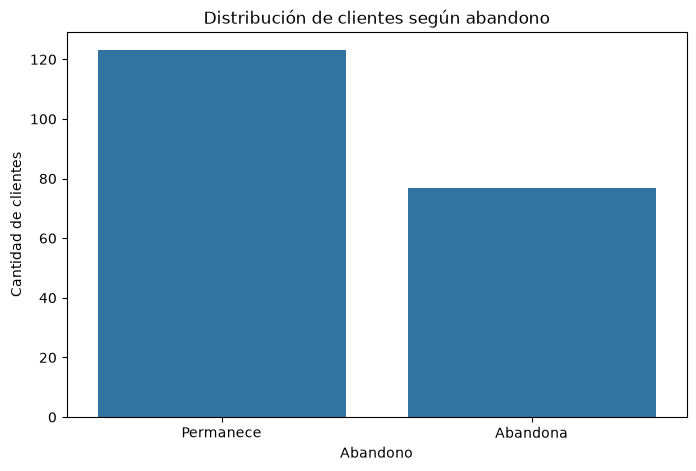

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="abandono"
)

plt.title("Distribución de clientes según abandono")
plt.xlabel("Abandono")
plt.ylabel("Cantidad de clientes")

plt.xticks(
    [0, 1],
    ["Permanece", "Abandona"]
)

plt.show()

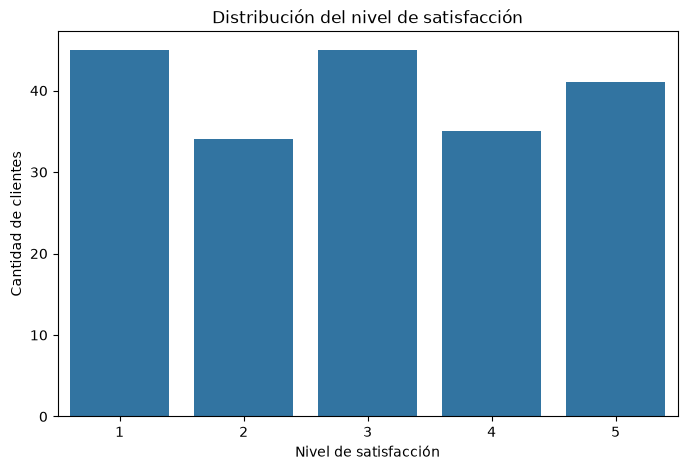

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="satisfaccion"
)

plt.title("Distribución del nivel de satisfacción")
plt.xlabel("Nivel de satisfacción")
plt.ylabel("Cantidad de clientes")

plt.show()

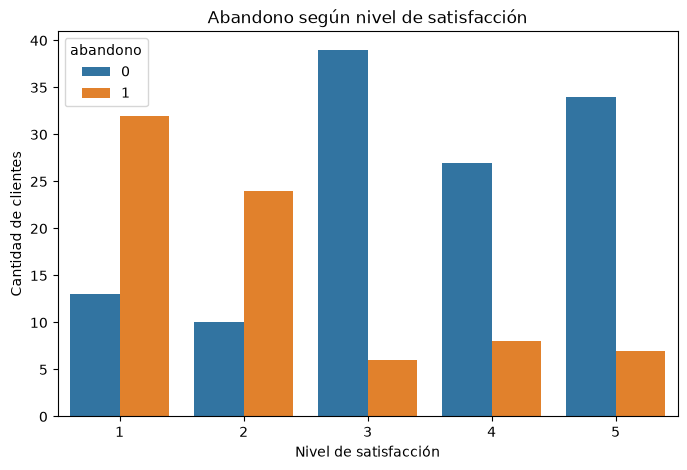

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="satisfaccion",
    hue="abandono"
)

plt.title("Abandono según nivel de satisfacción")
plt.xlabel("Nivel de satisfacción")
plt.ylabel("Cantidad de clientes")

plt.show()

# 6. Preparación de las variables para Machine Learning
Se definirán las variables predictoras (X) y la variable objetivo (y).

Las variables predictoras contienen las características utilizadas por el modelo para estimar el riesgo de abandono.

La variable objetivo representa si el cliente abandonó o permaneció en la empresa.

In [13]:
X = df[
    [
        "edad",
        "ingresos",
        "frecuencia_compra",
        "productos_adquiridos",
        "tiempo_cliente",
        "satisfaccion"
    ]
]

X.head()

,edad,ingresos,frecuencia_compra,productos_adquiridos,tiempo_cliente,satisfaccion
0,56,6897469,13,2,62,5
1,69,3435000,10,19,65,3
2,46,5522252,7,9,32,1
3,32,1602690,10,7,34,2
4,60,5893350,3,4,72,4


In [14]:
y = df["abandono"]

y.head()

0    0
1    0
2    1
3    0
4    1
Name: abandono, dtype: int32

In [15]:
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (200, 6)
Dimensiones de y: (200,)


In [16]:
y.value_counts()
y.value_counts()

abandono
0    123
1     77
Name: count, dtype: int64

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [18]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (160, 6)
X_test: (40, 6)
y_train: (160,)
y_test: (40,)


# 7. Modelo 1: Regresión Logística

Se utilizará un modelo de Regresión Logística como primer algoritmo de clasificación.

El modelo permitirá estimar la probabilidad de que un cliente pertenezca a la clase de abandono.

In [19]:
from sklearn.linear_model import LogisticRegression

modelo_logistico = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo_logistico.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [20]:
y_pred_logistico = modelo_logistico.predict(X_test)

y_pred_logistico[:10]

array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0], dtype=int32)

In [21]:
probabilidades_logistico = modelo_logistico.predict_proba(X_test)

probabilidades_logistico[:5]

array([[0.50574431, 0.49425569],
       [0.72103434, 0.27896566],
       [0.74283444, 0.25716556],
       [0.7928194 , 0.2071806 ],
       [0.3107992 , 0.6892008 ]])

In [22]:
from sklearn.metrics import accuracy_score

accuracy_logistico = accuracy_score(
    y_test,
    y_pred_logistico
)

print(
    f"Accuracy Regresión Logística: "
    f"{accuracy_logistico:.2%}"
)

Accuracy Regresión Logística: 75.00%


In [23]:
from sklearn.metrics import confusion_matrix

matriz_logistico = confusion_matrix(
    y_test,
    y_pred_logistico
)

matriz_logistico

array([[25,  0],
       [10,  5]])

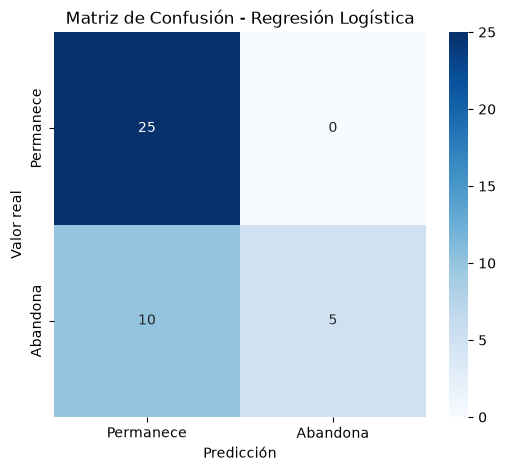

In [24]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_logistico,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Permanece", "Abandona"],
    yticklabels=["Permanece", "Abandona"]
)

plt.title("Matriz de Confusión - Regresión Logística")
plt.xlabel("Predicción")
plt.ylabel("Valor real")

plt.show()

In [25]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_logistico,
        target_names=["Permanece", "Abandona"]
    )
)

              precision    recall  f1-score   support

   Permanece       0.71      1.00      0.83        25
    Abandona       1.00      0.33      0.50        15

    accuracy                           0.75        40
   macro avg       0.86      0.67      0.67        40
weighted avg       0.82      0.75      0.71        40

